# Week 2 – Classification Models (Titanic)
Covers the assignment *“Train Logistic Regression on Titanic for survival prediction”* and the 4 practice questions:
1. Train a logistic regression model
2. Confusion matrix & accuracy
3. Compare DecisionTree vs KNN
4. Tune `max_depth` of Decision Tree

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report, ConfusionMatrixDisplay

df = pd.read_csv('data/titanic.csv')
print(df.shape); df.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## Preprocessing

In [2]:
data = df.copy()
data['Age'] = data['Age'].fillna(data['Age'].median())
data['Embarked'] = data['Embarked'].fillna(data['Embarked'].mode()[0])
data['Sex'] = data['Sex'].map({'male': 0, 'female': 1})
data['FamilySize'] = data['SibSp'] + data['Parch'] + 1
data = pd.get_dummies(data, columns=['Embarked'], drop_first=True)

features = ['Pclass','Sex','Age','Fare','FamilySize'] + [c for c in data.columns if c.startswith('Embarked_')]
X, y = data[features], data['Survived']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)
print('Features:', features)

Features: ['Pclass', 'Sex', 'Age', 'Fare', 'FamilySize', 'Embarked_Q', 'Embarked_S']


## Q1. Logistic Regression

In [3]:
log_reg = LogisticRegression(max_iter=1000).fit(X_train_s, y_train)
log_pred = log_reg.predict(X_test_s)
print(f'Logistic Regression accuracy: {accuracy_score(y_test, log_pred):.4f}')

Logistic Regression accuracy: 0.7989


## Q2. Confusion matrix & accuracy score

[[97 13]
 [23 46]]

              precision    recall  f1-score   support

        Died       0.81      0.88      0.84       110
    Survived       0.78      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.79      0.77      0.78       179
weighted avg       0.80      0.80      0.80       179



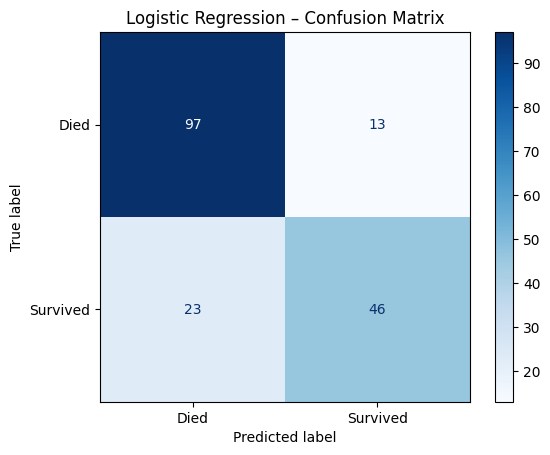

In [4]:
cm = confusion_matrix(y_test, log_pred)
print(cm); print()
print(classification_report(y_test, log_pred, target_names=['Died','Survived']))
ConfusionMatrixDisplay(cm, display_labels=['Died','Survived']).plot(cmap='Blues')
plt.title('Logistic Regression – Confusion Matrix'); plt.savefig('images/confusion_matrix.png', dpi=120); plt.show()

## Q3. DecisionTreeClassifier vs KNeighborsClassifier

In [5]:
tree = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
knn = KNeighborsClassifier(n_neighbors=5).fit(X_train_s, y_train)   # KNN needs scaled features

results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree (default)', 'KNN (k=5)'],
    'Accuracy': [accuracy_score(y_test, log_pred),
                 accuracy_score(y_test, tree.predict(X_test)),
                 accuracy_score(y_test, knn.predict(X_test_s))]
}).round(4)
results

,Model,Accuracy
0,Logistic Regression,0.7989
1,Decision Tree (default),0.8101
2,KNN (k=5),0.7933


## Q4. Tune `max_depth` of the Decision Tree

Default tree (no limit) test accuracy: 0.8101
Best max_depth = 3  ->  test accuracy 0.8045


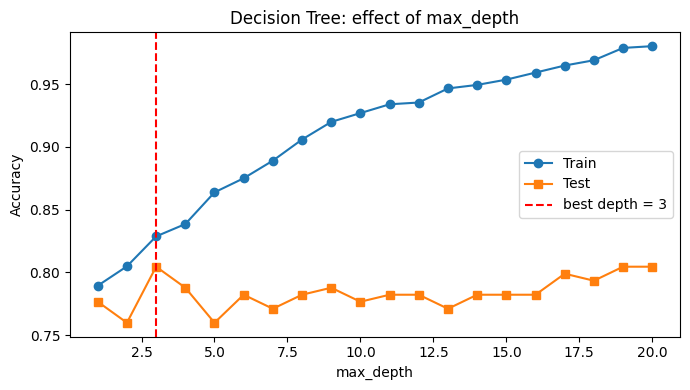

In [6]:
depths = range(1, 21)
train_acc, test_acc = [], []
for d in depths:
    t = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)
    train_acc.append(t.score(X_train, y_train)); test_acc.append(t.score(X_test, y_test))

best_d = list(depths)[int(np.argmax(test_acc))]
print(f'Default tree (no limit) test accuracy: {tree.score(X_test, y_test):.4f}')
print(f'Best max_depth = {best_d}  ->  test accuracy {max(test_acc):.4f}')

plt.figure(figsize=(7, 4))
plt.plot(depths, train_acc, 'o-', label='Train'); plt.plot(depths, test_acc, 's-', label='Test')
plt.axvline(best_d, color='r', ls='--', label=f'best depth = {best_d}')
plt.xlabel('max_depth'); plt.ylabel('Accuracy'); plt.title('Decision Tree: effect of max_depth'); plt.legend()
plt.tight_layout(); plt.savefig('images/max_depth_tuning.png', dpi=120); plt.show()

### Observations
- With **no depth limit** the tree fits the training data almost perfectly (train accuracy far above test accuracy) – the classic sign of **overfitting**, visible as the widening gap in the plot.
- **Very small depth** (1–2) is too simple and **underfits**.
- Test accuracy peaks at a shallow depth (printed above, `max_depth = 3`) and stays around 80%. On this small test set (179 rows) the differences between depths and the default tree are only a few passengers, so tuning mainly gives a **simpler, more stable tree** rather than a big accuracy jump.
- Logistic Regression, the tuned tree and KNN all land at roughly 79–81%; KNN needs scaled features and a sensible *k*.